# 02 Исследование и подготовка данных
[ShanghaiTech](https://github.com/desenzhou/ShanghaiTechDataset) — 1 198 JPEG с координатами голов в MAT. Part A содержит 482 изображения, Part B — 716. [MOT17](https://motchallenge.net/data/MOT17/) и [MOT20](https://motchallenge.net/data/MOT20/) — кадры видео с рамками пешеходов и ID. Используем 7 размеченных сцен MOT17 и 4 сцены MOT20. Дубликаты сцен MOT17 с другими детекторами исключены. Данных о начале обслуживания в этих наборах нет.


In [1]:
from collections import Counter
from configparser import ConfigParser
from hashlib import sha256
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.io import loadmat

data = Path("data")


## ShanghaiTech
Проверяем пары JPEG и MAT, удаляем точные дубликаты JPEG и считаем головы по точкам. Официальную тестовую часть сохраняем с удалением дубликатов. Валидацию выделяем из обучающих изображений по SHA-256, чтобы выборка не менялась между запусками. Проверка хеша выявляет побайтовые совпадения.


In [2]:
seen = set()
shanghai = {"A": [], "B": []}
for part, counts in shanghai.items():
    part_dir = next(data.joinpath("ShanghaiTech").rglob(f"part_{part}"))
    for split in ("train", "test"):
        directory = part_dir / f"{split}_data"
        ground_truth = next(p for p in directory.iterdir() if p.name in {"ground_truth", "ground-truth"})
        images = sorted((directory / "images").glob("*.jpg"))
        labels = {p.stem.removeprefix("GT_") for p in ground_truth.glob("GT_*.mat")}
        keys = {p.stem for p in images}
        duplicates = 0
        invalid = 0
        for image in images:
            if image.stem not in labels:
                continue
            digest = sha256(image.read_bytes()).hexdigest()
            if digest in seen:
                duplicates += 1
                continue
            path = ground_truth / f"GT_{image.stem}.mat"
            points = loadmat(path)["image_info"][0, 0][0, 0][0]
            valid = np.isfinite(points).all(axis=1)
            invalid += int((~valid).sum())
            group = "validation" if split == "train" and int(digest[:8], 16) % 5 == 0 else split
            counts.append((group, int(valid.sum())))
            seen.add(digest)
        print(part, split, "без MAT:", len(keys - labels), "без JPEG:", len(labels - keys),
              "дубликаты:", duplicates, "некорректные точки:", invalid)
    print("Разбиение", part, dict(Counter(group for group, _ in counts)))


A train без MAT: 0 без JPEG: 0 дубликаты: 0 некорректные точки: 0
A test без MAT: 0 без JPEG: 0 дубликаты: 1 некорректные точки: 0
Разбиение A {'train': 242, 'validation': 58, 'test': 181}
B train без MAT: 0 без JPEG: 0 дубликаты: 0 некорректные точки: 0
B test без MAT: 0 без JPEG: 0 дубликаты: 0 некорректные точки: 0
Разбиение B {'train': 323, 'validation': 77, 'test': 316}


## MOT
Разделяем по целым видео, чтобы одна траектория не попала в две части. Валидация — MOT17-09 и MOT20-03, локальный тест — MOT17-10, MOT17-13 и MOT20-05, остальные размеченные сцены — обучение. Проверяем диапазон кадров, размеры рамок и повторы кадр–ID. Для подсчёта оставляем пешеходов с `mark=1` и `class=1`.


In [3]:
scene_splits = {"MOT17-09": "validation", "MOT20-03": "validation",
                "MOT17-10": "test", "MOT17-13": "test", "MOT20-05": "test"}
mot = {"MOT17": [], "MOT20": []}
for dataset, collection in mot.items():
    pattern = "*-FRCNN" if dataset == "MOT17" else "*"
    classes = Counter()
    for scene in sorted((data / dataset / "train").glob(pattern)):
        name = scene.name.removesuffix("-FRCNN")
        info = ConfigParser()
        info.read(scene / "seqinfo.ini")
        frames = info["Sequence"].getint("seqLength")
        rows = np.loadtxt(scene / "gt/gt.txt", delimiter=",", ndmin=2)
        good = (np.isfinite(rows).all(axis=1) & (rows[:, 0] >= 1) & (rows[:, 0] <= frames)
                & (rows[:, 4:6] > 0).all(axis=1))
        clean = rows[good]
        _, unique = np.unique(clean[:, :2], axis=0, return_index=True)
        types = clean[unique, 7].astype(int)
        classes.update(types.tolist())
        people = clean[unique][(clean[unique, 6] == 1) & (types == 1)]
        counts = np.bincount(people[:, 0].astype(int), minlength=frames + 1)[1:]
        collection.extend(counts)
        print(name, scene_splits.get(name, "train"), "кадров:", frames,
              "ошибки:", int((~good).sum()), "повторы:", len(clean) - len(unique))
    print(dataset, "классы:", dict(sorted(classes.items())))


MOT17-02 train кадров: 600 ошибки: 0 повторы: 0
MOT17-04 train кадров: 1050 ошибки: 0 повторы: 0
MOT17-05 train кадров: 837 ошибки: 0 повторы: 0
MOT17-09 validation кадров: 525 ошибки: 0 повторы: 0
MOT17-10 test кадров: 654 ошибки: 0 повторы: 0
MOT17-11 train кадров: 900 ошибки: 0 повторы: 0
MOT17-13 test кадров: 750 ошибки: 0 повторы: 0
MOT17 классы: {1: 112297, 2: 1864, 3: 6189, 4: 13527, 5: 1050, 6: 11, 7: 12041, 8: 3595, 9: 3724, 10: 28573, 11: 19580, 12: 2250}
MOT20-01 train кадров: 429 ошибки: 0 повторы: 0


MOT20-02 train кадров: 2782 ошибки: 0 повторы: 0


MOT20-03 validation кадров: 2405 ошибки: 0 повторы: 0


MOT20-05 test кадров: 3315 ошибки: 0 повторы: 0
MOT20 классы: {1: 1134614, 6: 12970, 7: 126855, 11: 59992, 13: 2489}


MOT17 медиана людей в кадре: 16.0
MOT20 медиана людей в кадре: 124.0


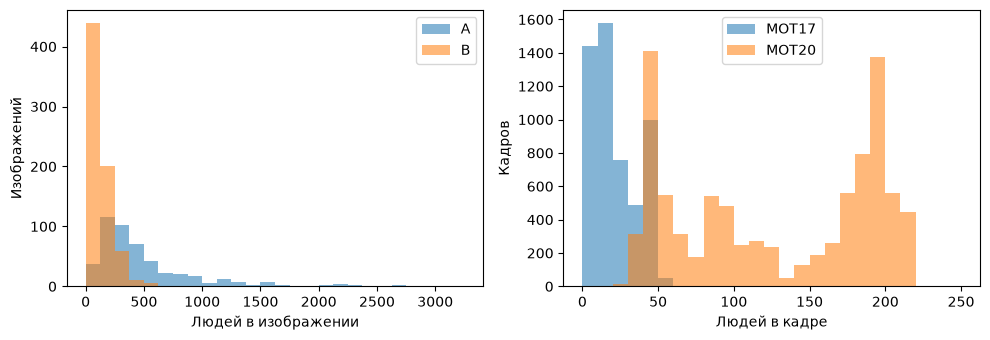

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for part, counts in shanghai.items():
    axes[0].hist([count for _, count in counts], bins=range(0, 3251, 125), alpha=.55, label=part)
for dataset, counts in mot.items():
    axes[1].hist(counts, bins=range(0, 251, 10), alpha=.55, label=dataset)
    print(dataset, "медиана людей в кадре:", np.median(counts))
axes[0].set(xlabel="Людей в изображении", ylabel="Изображений")
axes[1].set(xlabel="Людей в кадре", ylabel="Кадров")
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()


В MOT20 фоновые сцены заметно плотнее, поэтому результаты считаем отдельно по датасетам. Для очереди потребуется видео с разметкой входа в зону ожидания и начала обслуживания.
